# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Pasion, Kyla Zarina
- _Student No._: 2024-09224
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<div align="center">
<img src="e12_figure1.png" alt="Alt text" width=80%> 
    
**Figure 1. Initial spin configurations** Initial 20×20 spin lattice configurations for four different random seeds, exhibiting completely disordered states with near-zero initial magnetization.

<img src="e12_figure2.png" alt="Alt text" width=80%> 

**Figure 2. Spin configurations after 10,000 sweeps** Final spin configurations of the lattice after 10,000 Monte Carlo sweeps. The left panel shows an ordered ferromagnetic state below the critical temperature ($T = 1.0$), while the right panel shows a disordered paramagnetic state above the critical temperature ($T = 3.5$).

<img src="e12_figure3.png" alt="Alt text" width=80%> 
<img src="e12_figure5.png" alt="Alt text" width=80%> 

**Figure 3. Magnetization per spin and total energy versus Monte Carlo sweeps with $B=0$** Final spin configurations of the lattice after 10,000 Monte Carlo sweeps. The left panel shows an ordered ferromagnetic state below the critical temperature ($T = 1.0$), while the right panel shows a disordered paramagnetic state above the critical temperature ($T = 3.5$).

<img src="e12_figure4.png" alt="Alt text" width=80%> 
<img src="e12_figure6.png" alt="Alt text" width=80%> 

**Figure 4. Magnetization per spin and total energy versus Monte Carlo sweeps with $B=0.5$** Evolution of magnetization and total energy over 5,000 sweeps with an applied external magnetic field ($B = 0.5$). At $T = 1.0$, the field forces all seeds to rapidly align in the positive direction, while at $T = 3.5$, thermal noise prevents complete alignment, causing the magnetization to fluctuate around a lower positive average.
</div>

### Report discussion

The Monte Carlo simulation effectively captures the phase transition and thermodynamic behavior of the 2D Ising model. As seen in Figure 1, the simulations begin with randomly initialized 20×20 lattices, representing a high-energy, completely disordered state where the number of up (+1) and down (-1) spins are roughly equal. Because the interactions are localized to nearest neighbors, these initial states yield total energies close to zero and negligible net magnetization. This random initialization ensures that any subsequent ordering observed during the Metropolis sweeps is a result of the system's inherent physical properties and the applied environmental parameters ($T$ and $B$), rather than an initial bias.   

Figure 3  contrasts the system's evolution under zero external magnetic field at temperatures below and above the critical threshold ($T_C \approx 2.269$). When the temperature is set to $T = 1.0$, the spin-spin interaction energy dominates over the thermal energy, causing the system to undergo spontaneous symmetry breaking. The lattice minimizes its total energy by aligning its spins, but without an external preference, it randomly falls into either a net positive ($m \approx +1$) or net negative ($m \approx -1$) magnetization state depending on the initial seed. Conversely, heating the system to $T = 3.5$ destroys the magnetic ordering entirely; thermal energy fluctuations ($k_B T$) overcome the local nearest-neighbor interactions, causing the total energy to fluctuate chaotically and the magnetization to rapidly oscillate around zero.   

These contrasting zero-field regimes are visually confirmed in Figure 2. After 10,000 sweeps at $T = 1.0$, the lattice becomes almost entirely uniform, settling into a deep energy minimum representing long-range ferromagnetic order. At $T = 3.5$, the lattice remains a thoroughly mixed paramagnetic state where neither spin direction can establish long-range dominance.   

Introducing an external magnetic field explicitly breaks spatial symmetry and alters this dynamic, as illustrated in Figure 4. Applying a field of $B = 0.5$ at $T = 1.0$ heavily favors spins that align parallel to the field, causing all initial configurations to rapidly converge to a uniform state of $m = +1$ and a highly stable energy minimum ($H \approx -1000$). At the higher temperature of $T = 3.5$, the external field still biases the spins to align positively, but the intense thermal fluctuations prevent total uniform alignment. As a result, the magnetization fluctuates around a positive average ($m \approx 0.6$) rather than locking in at +1, demonstrating the competing effects of magnetic field alignment and thermal disorder. 

### Other comments
- This activity helped me understand the underlying physics concepts of spins and magnetization through visualization. It is also a fascinating and great introductory activity on how to apply Monte Carlo methods.


# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap



## Setting up the Ising Model

In [2]:
# Parameters
N = 20
J = 1.0
T = 1.0
kB = 1.0
B = 0.0
Tc = 2.269 * J / kB
sweeps_mE = 5000
seeds = [42, 15, 99, 123]
seed = 42
sweeps = 10000 
flips = N**2
steps = sweeps * flips

In [3]:
# Building a random lattice
def create_lattice(N, rng):
    return rng.choice([-1,1], size=(N,N))

# Total energy
def calculate_ham(grid, J, B):
    right = np.roll(grid, shift=-1, axis=1) # S_{i,j+1}
    bottom = np.roll(grid, shift=-1, axis=0) # S_{i+1,j}
    total_interaction = np.sum(grid * (right + bottom))
    
    # H = -J * sum(S_i S_j) - B * sum(S_i)
    return -J * total_interaction - B * np.sum(grid)


### Problem 1 code summary

The code initializes a 20×20 lattice with randomly assigned up and down spins, representing a 2D Ising model, and calculates its initial energy to examine the development of magnetic ordering. The energy calculation uses `np.roll` to match each spin with its neighbors below and to the right, ensuring that each interaction is counted only once while applying periodic boundary conditions. This allows the lattice edges to wrap around, preventing boundary effects. 

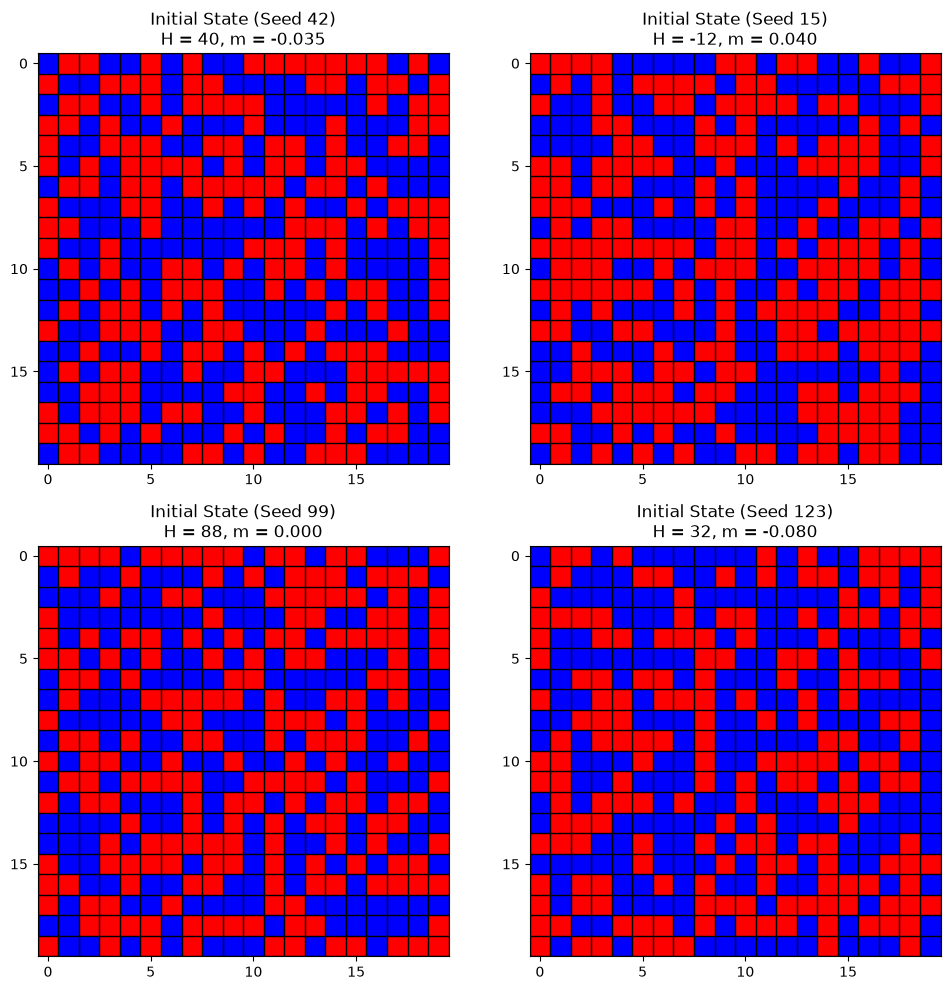

In [4]:
def magnetization(grid):
    return np.sum(grid) / (N**2)

def plot_grid(ax, grid, title):
    cmap = ListedColormap(['blue', 'red'])
    im = ax.imshow(grid, cmap=cmap, vmin=-1, vmax=1)

    ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
    ax.grid(which='minor', color='black', linestyle='-', linewidth=1)
    ax.tick_params(which='minor', bottom=False, left=False)

    ax.set_xticks(np.arange(0, N, 5))
    ax.set_yticks(np.arange(0, N, 5))
    ax.set_title(title)
    return im

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, s in zip(axes.ravel(), seeds):
    rng_init = np.random.default_rng(s)
    grid_init = create_lattice(N, rng_init)
    
    H_init = calculate_ham(grid_init, J, B)
    m_init = magnetization(grid_init)
    
    plot_grid(ax, grid_init, f'Initial State (Seed {s})\nH = {H_init:.0f}, m = {m_init:.3f}')

plt.tight_layout()
plt.savefig("e12_figure1")
plt.show()

## Implementating the Metropolis Algorithm

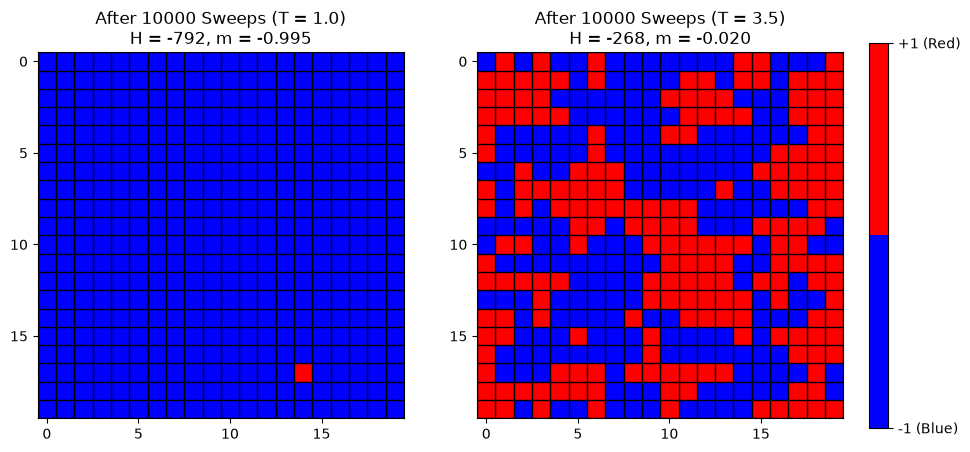

In [5]:
def metropolis_alg(grid, J, T, kB, B, rng):
    size = grid.shape[0]
    
    i = rng.integers(0, size)
    j = rng.integers(0, size)
    spin = grid[i, j]

    neighbors = (
        grid[(i-1) % size, j] + 
        grid[(i+1) % size, j] + 
        grid[i, (j-1) % size] + 
        grid[i, (j+1) % size]   
    )

    dH = 2.0 * spin * (J * neighbors + B)

    if dH <= 0 or rng.random() < np.exp(-dH / (kB * T)):
        grid[i, j] = -spin

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
T_vals = [1.0, 3.5]
ims = []

for ax, T_val in zip(axes, T_vals):
    rng_end = np.random.default_rng(seed)
    grid_end = create_lattice(N, rng_end)
    
    for _ in range(steps):
        metropolis_alg(grid_end, J, T_val, kB, 0.0, rng_end)
        
    H_end = calculate_ham(grid_end, J, B)
    m_end = magnetization(grid_end)
    
    im = plot_grid(ax, grid_end, f'After {sweeps} Sweeps (T = {T_val})\nH = {H_end:.0f}, m = {m_end:.3f}')
    ims.append(im)

cbar = fig.colorbar(
    ims[0], ax=axes.ravel().tolist(), ticks=[-1, 1], fraction=0.025, pad=0.03)
cbar.ax.set_yticklabels(['-1 (Blue)', '+1 (Red)'])
fig.savefig("e12_figure2.png", dpi=300, bbox_inches='tight')
plt.show()

### Problem 2 code summary

This code implements the Metropolis algorithm to simulate the 2D Ising model by randomly selecting a spin and flipping it whenever the change reduces the system's energy. If the flip increases the energy, it is accepted based on the probability $e^{-\Delta H/k_BT}$, allowing the lattice to approach thermal equilibrium at a specified temperature. To improve efficiency over 10,000 sweeps, the algorithm calculates the energy difference $\Delta H$ using only the selected spin's four nearest neighbors. After all the sweeps are completed, it recalculates the final total energy and magnetization of the entire lattice to observe the system's thermal equilibrium state.

## Investigating spontaneous magnetization


--- Running for T=1.0, B=0.0 ---
Seed  42: start m = -0.035, final <m> = +0.999, final <H> = -798.8
Seed  15: start m = -0.115, final <m> = -0.999, final <H> = -798.6
Seed  99: start m = +0.110, final <m> = +0.999, final <H> = -799.0
Seed 123: start m = -0.160, final <m> = -0.999, final <H> = -799.0


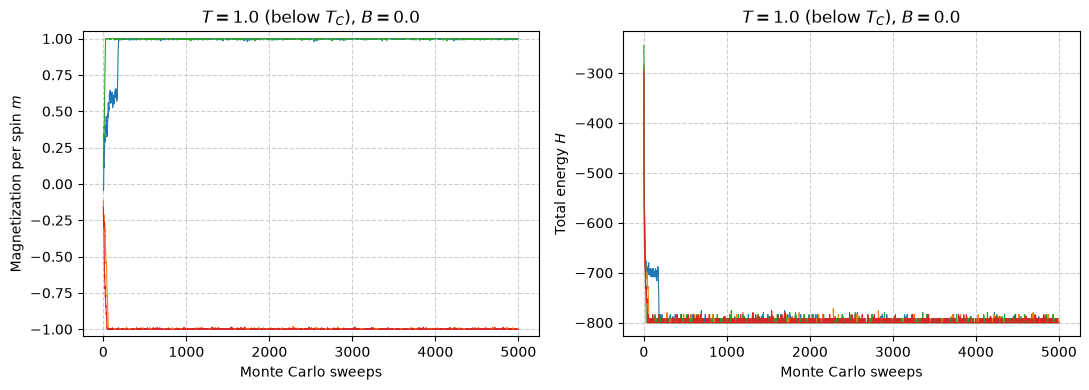

In [6]:
def run_seeds(T, B):
    runs = []
    print(f"\n--- Running for T={T}, B={B} ---")
    for s in seeds:
        rng_lattice = np.random.default_rng(s)
        rng_flip = np.random.default_rng(s + 100)
        
        S_init = create_lattice(N, rng_lattice)
        
        ms = []
        Es = []
        
        for sweep in range(sweeps_mE):
            for _ in range(N**2):
                metropolis_alg(S_init, J, T, kB, B, rng_flip)
            
            ms.append(magnetization(S_init))
            Es.append(calculate_ham(S_init, J, B))
            
        ms = np.array(ms)
        Es = np.array(Es)
        runs.append((ms, Es))
        
        print(f"Seed {s:3d}: start m = {ms[0]:+.3f}, "
              f"final <m> = {ms[-500:].mean():+.3f}, final <H> = {Es[-500:].mean():.1f}")
        
    return runs

figure_num = 3

def plot_mE(runs, T, B):
    global figure_num
    side = "below" if T < Tc else "above"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    
    for s, (ms, Es) in zip(seeds, runs):
        ax1.plot(ms, lw=0.8, label=f"Seed {s}")
        ax2.plot(Es, lw=0.8, label=f"Seed {s}")
        
    ax1.set_ylim(-1.05, 1.05)
    ax1.set_ylabel("Magnetization per spin $m$")
    ax2.set_ylabel("Total energy $H$")
    
    for ax in (ax1, ax2):
        ax.set_xlabel("Monte Carlo sweeps")
        ax.set_title(f"$T = {T}$ ({side} $T_C$), $B = {B}$")
        ax.grid(True, linestyle='--', alpha=0.6)
        
    plt.tight_layout()
    fig.savefig(f"e12_figure{figure_num}.png", dpi=300, bbox_inches='tight')
    figure_num += 1
    plt.show()

runs_task3 = run_seeds(T=1.0, B=0.0)
plot_mE(runs_task3, T=1.0, B=0.0)

### Problem 3 code summary

This code examines the evolution of the Ising lattice by performing the Metropolis simulation using four different random initial configurations (seeds) and recording the magnetization per spin and total energy after each sweep. Running multiple seeds helps determine whether the results are influenced by the initial configuration or reflect the system's underlying physical behavior. The averages over the final 500 sweeps provide more representative equilibrium values by excluding the initial transient period. The plotting function displays magnetization and energy side by side as functions of the number of sweeps, illustrating how the spins become ordered at low temperatures or remain disordered at high temperatures.

## Introducing an external magnetic field


--- Running for T=1.0, B=0.5 ---
Seed  42: start m = +0.255, final <m> = +1.000, final <H> = -999.6
Seed  15: start m = +0.175, final <m> = +1.000, final <H> = -999.6
Seed  99: start m = +0.215, final <m> = +1.000, final <H> = -999.6
Seed 123: start m = +0.160, final <m> = +1.000, final <H> = -999.6


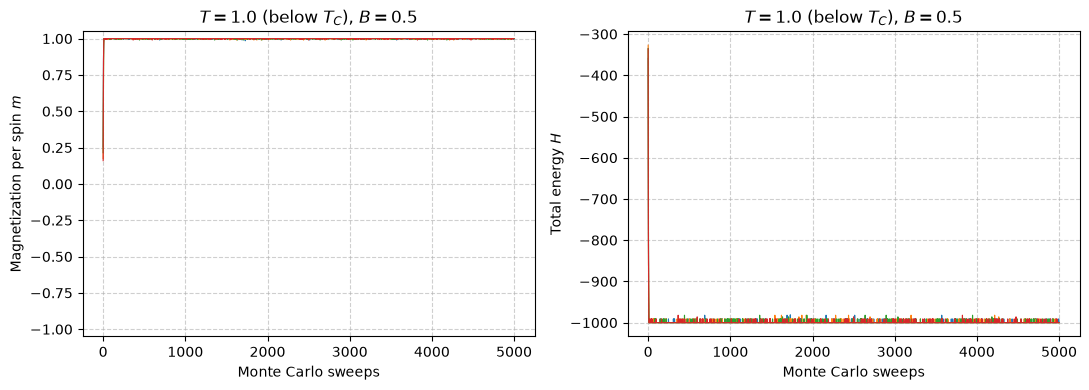

In [7]:
runs_task4 = run_seeds(T=1.0, B=0.5)
plot_mE(runs_task4, T=1.0, B=0.5)

### Problem 4 code summary

This code repeats the simulation while applying an external magnetic field of $B = 0.5$. No changes to the algorithm are necessary since the field contribution is already included in the energy calculation and Metropolis flip rule, $\Delta H = 2s(J \cdot \text{neighbors} + B)$. Adjusting the value of $B$ is sufficient to account for the external field, which favors spins pointing in the positive direction ($+1$). As a result, the four randomly initialized lattices are expected to develop positive magnetization rather than settling in either direction, as observed when $B = 0$. This behavior is reflected in the resulting plots.

## Critical Temperature


--- Running for T=3.5, B=0.0 ---
Seed  42: start m = +0.075, final <m> = +0.004, final <H> = -268.0
Seed  15: start m = +0.010, final <m> = +0.013, final <H> = -262.4
Seed  99: start m = +0.010, final <m> = -0.025, final <H> = -265.8
Seed 123: start m = +0.060, final <m> = +0.002, final <H> = -263.4


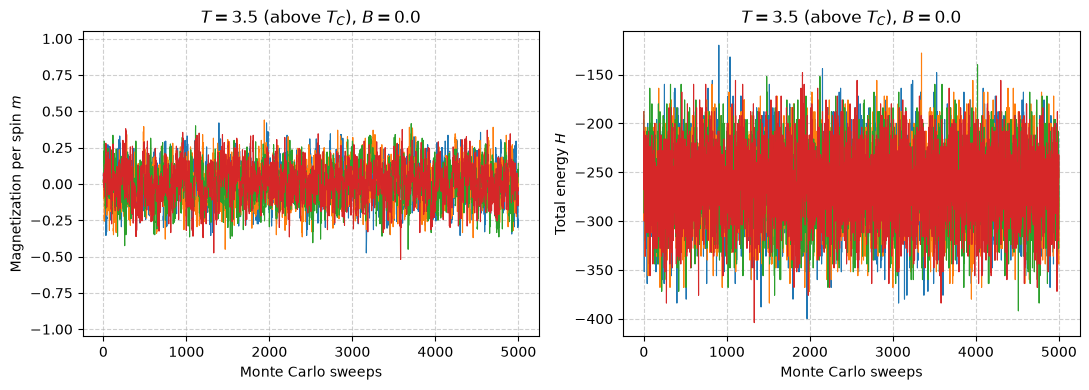


--- Running for T=3.5, B=0.5 ---
Seed  42: start m = +0.140, final <m> = +0.597, final <H> = -529.2
Seed  15: start m = +0.245, final <m> = +0.609, final <H> = -537.4
Seed  99: start m = +0.115, final <m> = +0.595, final <H> = -526.7
Seed 123: start m = +0.095, final <m> = +0.587, final <H> = -523.2


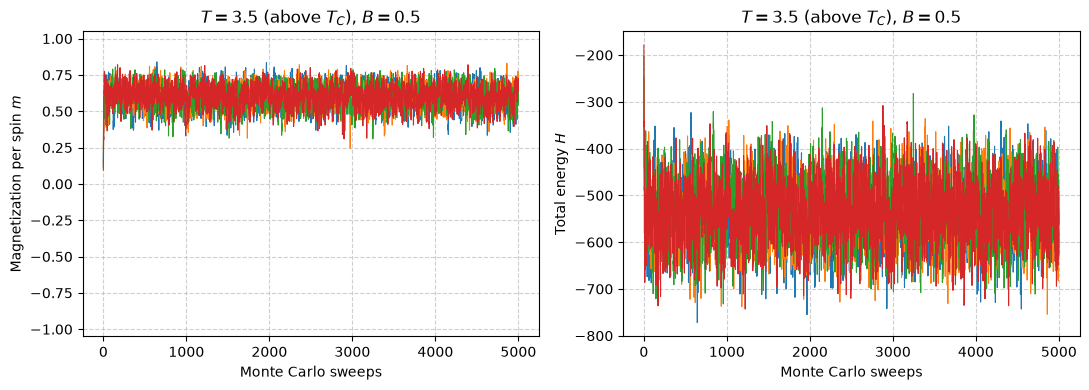

In [8]:
# T = 3.5 (Above Tc), B = 0.0
runs_task5_B0 = run_seeds(T=3.5, B=0.0)
plot_mE(runs_task5_B0, T=3.5, B=0.0)

# T = 3.5 (Above Tc), B = 0.5
runs_task5_B05 = run_seeds(T=3.5, B=0.5)
plot_mE(runs_task5_B05, T=3.5, B=0.5)

### Problem 5 code summary

This code repeats the previous simulations at $T = 3.5$, which is above the critical temperature of approximately $T_C = 2.269$, allowing the results to be compared with those obtained at $T = 1.0$. It reuses the same simulation and plotting functions while changing only the temperature to maintain consistency between the experiments. The low- and high-temperature results are then presented in corresponding figures to make the differences in their magnetic behavior easier to observe.